# Machine Learning Assignment 2 — Telco Customer Churn Classification

**Name:** Mokka Hema Sai

**ID:** 2026CT05096

**Programme:** M.Tech (AIML), BITS Pilani  
**Task:** Implement and compare five classification models on one dataset.

## Problem statement
Predict whether a telecommunications customer will churn (`Churn = Yes`) using customer account, service and billing attributes.

## Dataset
IBM Telco Customer Churn dataset (`WA_Fn-UseC_-Telco-Customer-Churn.csv`). The supplied CSV is expected to contain 7,043 records, 21 columns, a `customerID` identifier and a `Churn` target.

**Target:** `Churn`  
**Positive class:** `Yes` (customer churns)  
**Models:** Logistic Regression, Decision Tree, K-Nearest Neighbors, Gaussian Naive Bayes and Random Forest.



## 1. Environment and imports


In [17]:
#from google.colab import files
#uploaded = files.upload()

from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
import joblib

RANDOM_STATE = 42
DATA_PATH = Path("WA_Fn-UseC_-Telco-Customer-Churn.csv")

if not DATA_PATH.exists():
    # In Colab, open an upload picker if the CSV is not already present.
    try:
        from google.colab import files
        print("Please upload WA_Fn-UseC_-Telco-Customer-Churn.csv")
        uploaded = files.upload()
        csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
        if csv_names:
            DATA_PATH = Path(csv_names[0])
    except ImportError:
        pass

if not DATA_PATH.exists():
    candidates = list(Path(".").glob("*.csv"))
    if len(candidates) == 1:
        DATA_PATH = candidates[0]
    else:
        raise FileNotFoundError(
            "CSV not found. Upload WA_Fn-UseC_-Telco-Customer-Churn.csv "
            "or set DATA_PATH to its location."
        )

print("Using dataset:", DATA_PATH.resolve())


Using dataset: /content/WA_Fn-UseC_-Telco-Customer-Churn.csv


## 2. Load and inspect the dataset

In [18]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
display(df.info())
display(df.describe(include="all").T)


Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2.1 Validate required columns and data quality

The `TotalCharges` column is stored as text in the original file. Blank strings (including whitespace-only cells) must be converted to missing numeric values before imputation.


In [19]:
required_columns = {"customerID", "Churn", "TotalCharges"}
missing_required = required_columns - set(df.columns)
if missing_required:
    raise ValueError(f"Dataset is missing required columns: {missing_required}")

# Convert whitespace-only values to NaN, then convert TotalCharges to numeric.
df = df.replace(r"^\\s*$", np.nan, regex=True)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())


Missing values by column:


,missing_count
TotalCharges,11
gender,0
SeniorCitizen,0
Partner,0
customerID,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0


Duplicate rows: 0
Duplicate customer IDs: 0


### 2.2 Handle duplicate records

We remove exact duplicate rows, if present. `customerID` is an identifier and is not used as a predictive feature. We retain it only for data inspection, then drop it from the modelling features.


In [20]:
rows_before = len(df)
df = df.drop_duplicates().copy()
print(f"Removed {rows_before - len(df)} exact duplicate rows.")
print("Shape after duplicate handling:", df.shape)

if df["Churn"].isna().any():
    raise ValueError("Target contains missing values; investigate before modelling.")

print("Target values:", sorted(df["Churn"].astype(str).unique()))


Removed 0 exact duplicate rows.
Shape after duplicate handling: (7043, 21)
Target values: ['No', 'Yes']


## 3. Exploratory data analysis

,count,percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


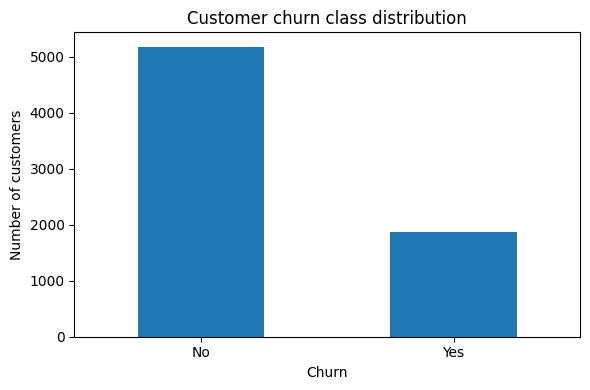

Number of input features: 19
Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Total numerical: 4
Total categorical: 15


In [21]:
# Target distribution and proportions
target_counts = df["Churn"].value_counts().reindex(["No", "Yes"])
target_percent = df["Churn"].value_counts(normalize=True).reindex(["No", "Yes"]) * 100

display(pd.DataFrame({
    "count": target_counts,
    "percentage": target_percent.round(2)
}))

ax = target_counts.plot(kind="bar", rot=0, figsize=(6, 4))
ax.set_title("Customer churn class distribution")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

# Identify feature types (excluding identifier and target)
feature_columns = [c for c in df.columns if c not in ["customerID", "Churn"]]
numeric_columns = df[feature_columns].select_dtypes(include=["number"]).columns.tolist()
categorical_columns = [c for c in feature_columns if c not in numeric_columns]

print("Number of input features:", len(feature_columns))
print("Numerical features:", numeric_columns)
print("Categorical features:", categorical_columns)
print("Total numerical:", len(numeric_columns))
print("Total categorical:", len(categorical_columns))


### 3.1 Dataset selection rationale

The dataset is suitable for this assignment because it is a binary classification problem with thousands of customer records and a mixture of numerical and categorical predictors. It allows us to demonstrate missing-value handling, categorical encoding, scaling and class-imbalance-aware evaluation.

**Write a short explanation in your own words after reviewing the dataset:**  
- Why is churn prediction useful to a telecom business?
- Which customer attributes might be associated with churn?


## 4. Prepare features and target

`customerID` is excluded because it is an identifier rather than a meaningful customer behaviour variable. The target is encoded as 0 = No and 1 = Yes so that churn is the positive class for precision, recall, F1 and MCC.


In [22]:
X = df.drop(columns=["customerID", "Churn"]).copy()
y = df["Churn"].map({"No": 0, "Yes": 1})

if y.isna().any():
    raise ValueError("Unexpected target labels. Expected only 'No' and 'Yes'.")

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Positive class (Churn=Yes) proportion:", round(y.mean() * 100, 2), "%")


X shape: (7043, 19)
y shape: (7043,)
Positive class (Churn=Yes) proportion: 26.54 %


## 5. Train-test split (80:20)

We use stratification to preserve the class distribution in both partitions. The random seed is fixed at 42 for reproducibility. The test set is held out and is not used to fit preprocessing or models.


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape, " Test set:", X_test.shape)
print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())
print("\nTest target proportions:")
display(y_test.value_counts(normalize=True).rename("proportion").to_frame())


Training set: (5634, 19)  Test set: (1409, 19)

Training target proportions:


,proportion
Churn,
0,0.734647
1,0.265353



Test target proportions:


,proportion
Churn,
0,0.734564
1,0.265436


## 6. Preprocessing pipelines

Numerical columns: median imputation followed by standard scaling.  
Categorical columns: most-frequent imputation followed by one-hot encoding.

All transformations are placed inside a `ColumnTransformer` and fitted as part of each model pipeline. Therefore, imputation statistics, scaling parameters and category levels are learned from the training partition only. The encoder is configured to ignore unseen categories in the test data.

A dense one-hot matrix is used so that Gaussian Naive Bayes can consume the transformed data. This dataset is small enough for this approach.


In [24]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_columns),
        ("cat", categorical_pipeline, categorical_columns)
    ],
    remainder="drop"
)

print("Preprocessing pipeline defined.")


Preprocessing pipeline defined.


## 7. Define the five classification models

The configurations below are reasonable starting points, not claims that these are universally optimal. Class weighting is used for Logistic Regression, Decision Tree and Random Forest to make the models account for the less frequent churn class. KNN and Gaussian Naive Bayes do not expose the same `class_weight` option; their results should be interpreted with this limitation in mind.

All models use the same train-test split and the same preprocessing strategy.


In [25]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE, class_weight="balanced"
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5, weights="uniform"
    ),
    "Gaussian Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE,
        class_weight="balanced", n_jobs=-1
    )
}

pipelines = {
    name: Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", estimator)
    ])
    for name, estimator in models.items()
}

print("Models prepared:", list(pipelines.keys()))


Models prepared: ['Logistic Regression', 'Decision Tree', 'K-Nearest Neighbors', 'Gaussian Naive Bayes', 'Random Forest']


## 8. Train models and calculate evaluation metrics

For every model, we calculate Accuracy, ROC-AUC, Precision, Recall, F1 and Matthews Correlation Coefficient (MCC). The positive class is `Churn = Yes` (label 1).

AUC is calculated using predicted probabilities. All other threshold-based metrics use the model's default class prediction threshold/decision rule.


In [26]:
results = []
fitted_models = {}
predictions = {}
probabilities = {}

for name, pipeline in pipelines.items():
    print(f"Training {name} ...")
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    fitted_models[name] = pipeline
    predictions[name] = y_pred
    probabilities[name] = y_prob

    results.append({
        "ML Model Name": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

results_df = pd.DataFrame(results).set_index("ML Model Name")
display(results_df.round(4))


Training Logistic Regression ...
Training Decision Tree ...
Training K-Nearest Neighbors ...
Training Gaussian Naive Bayes ...
Training Random Forest ...


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.7381,0.8413,0.5043,0.7834,0.6136,0.4531
Decision Tree,0.7282,0.6496,0.4878,0.4813,0.4845,0.3000
K-Nearest Neighbors,0.7637,0.7895,0.5527,0.5749,0.5636,0.4018
Gaussian Naive Bayes,0.6948,0.8074,0.4589,0.8369,0.5928,0.4245
Random Forest,0.7814,0.8217,0.6170,0.4652,0.5305,0.3983


## 9. Visual comparison of all six metrics

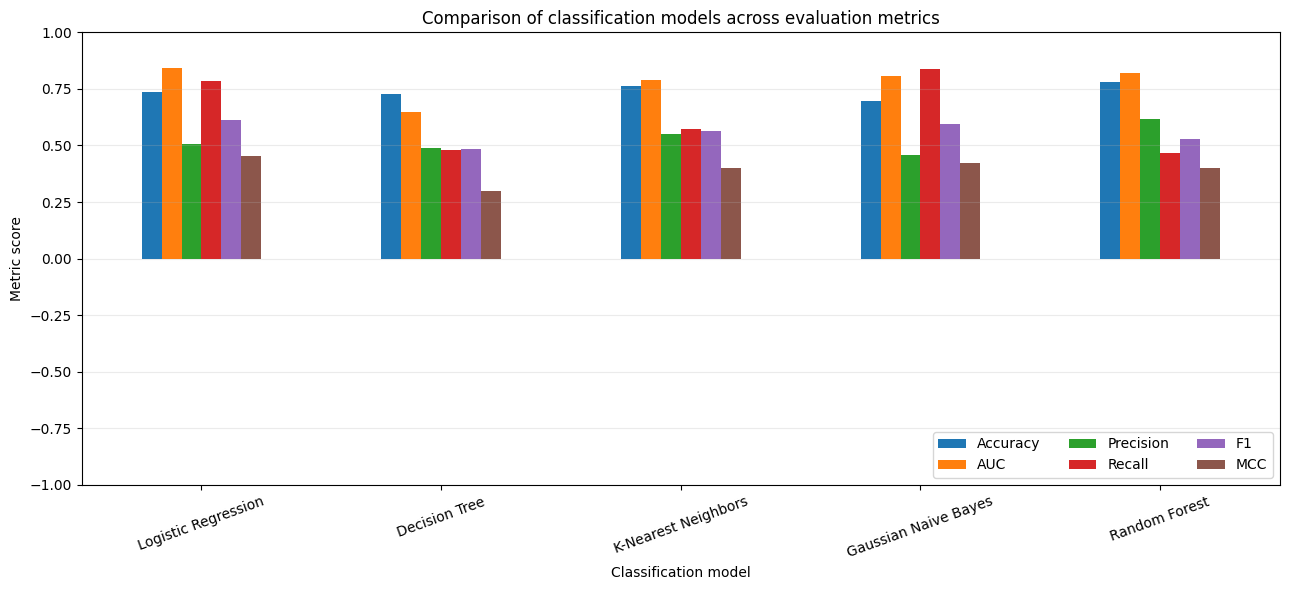

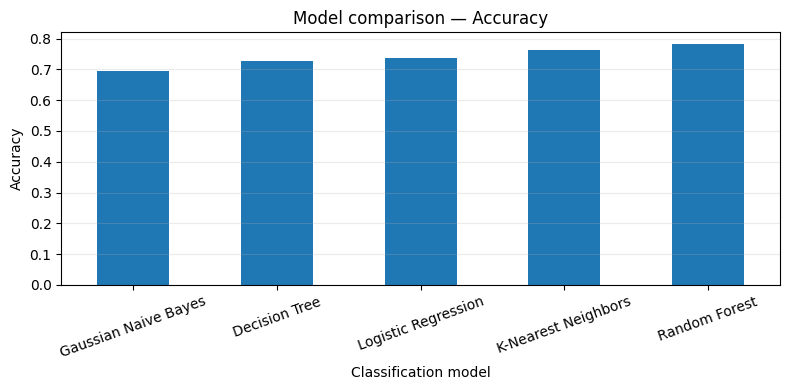

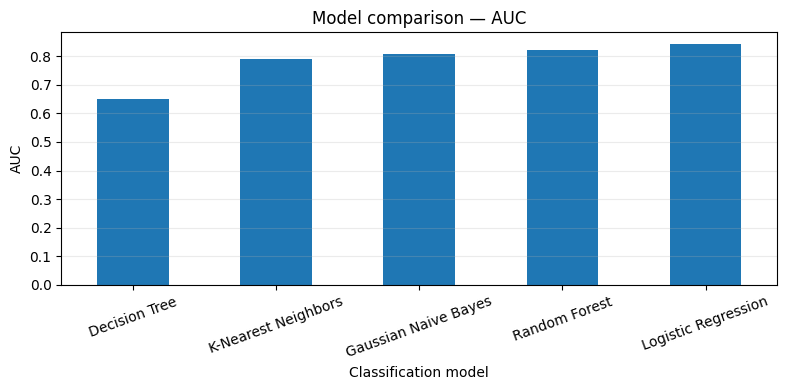

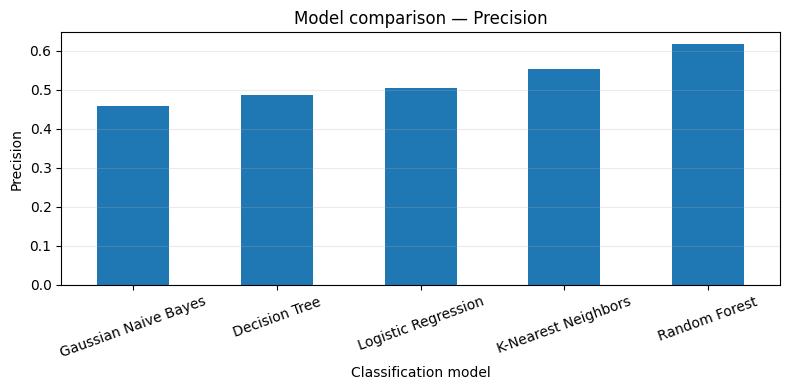

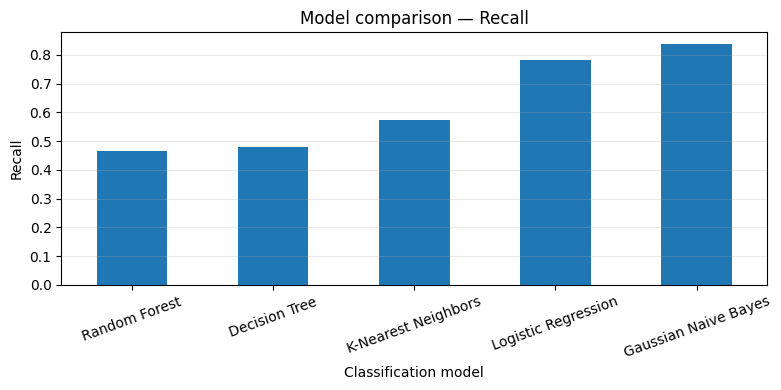

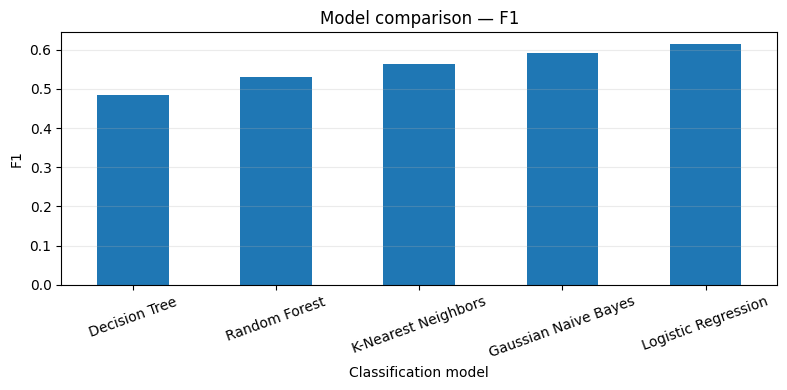

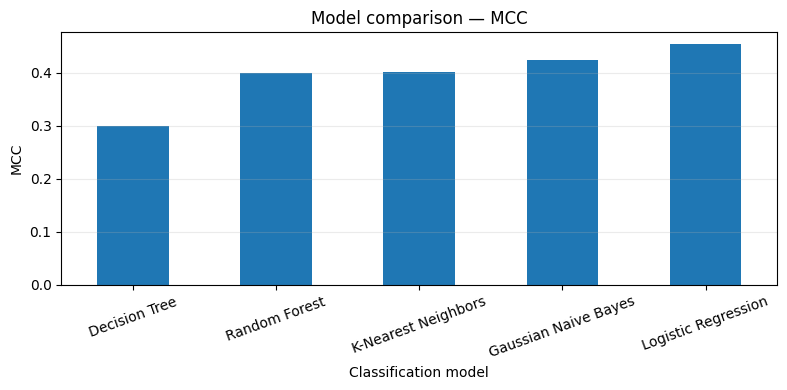

In [27]:
ax = results_df.plot(kind="bar", figsize=(13, 6), ylim=(-1, 1), rot=20)
ax.set_title("Comparison of classification models across evaluation metrics")
ax.set_xlabel("Classification model")
ax.set_ylabel("Metric score")
ax.legend(loc="lower right", ncol=3)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Individual metric charts make small differences easier to inspect.
for metric in results_df.columns:
    ax = results_df[metric].sort_values().plot(
        kind="bar", figsize=(8, 4), rot=20, title=f"Model comparison — {metric}"
    )
    ax.set_ylabel(metric)
    ax.set_xlabel("Classification model")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()


## 10. Confusion matrices and classification reports

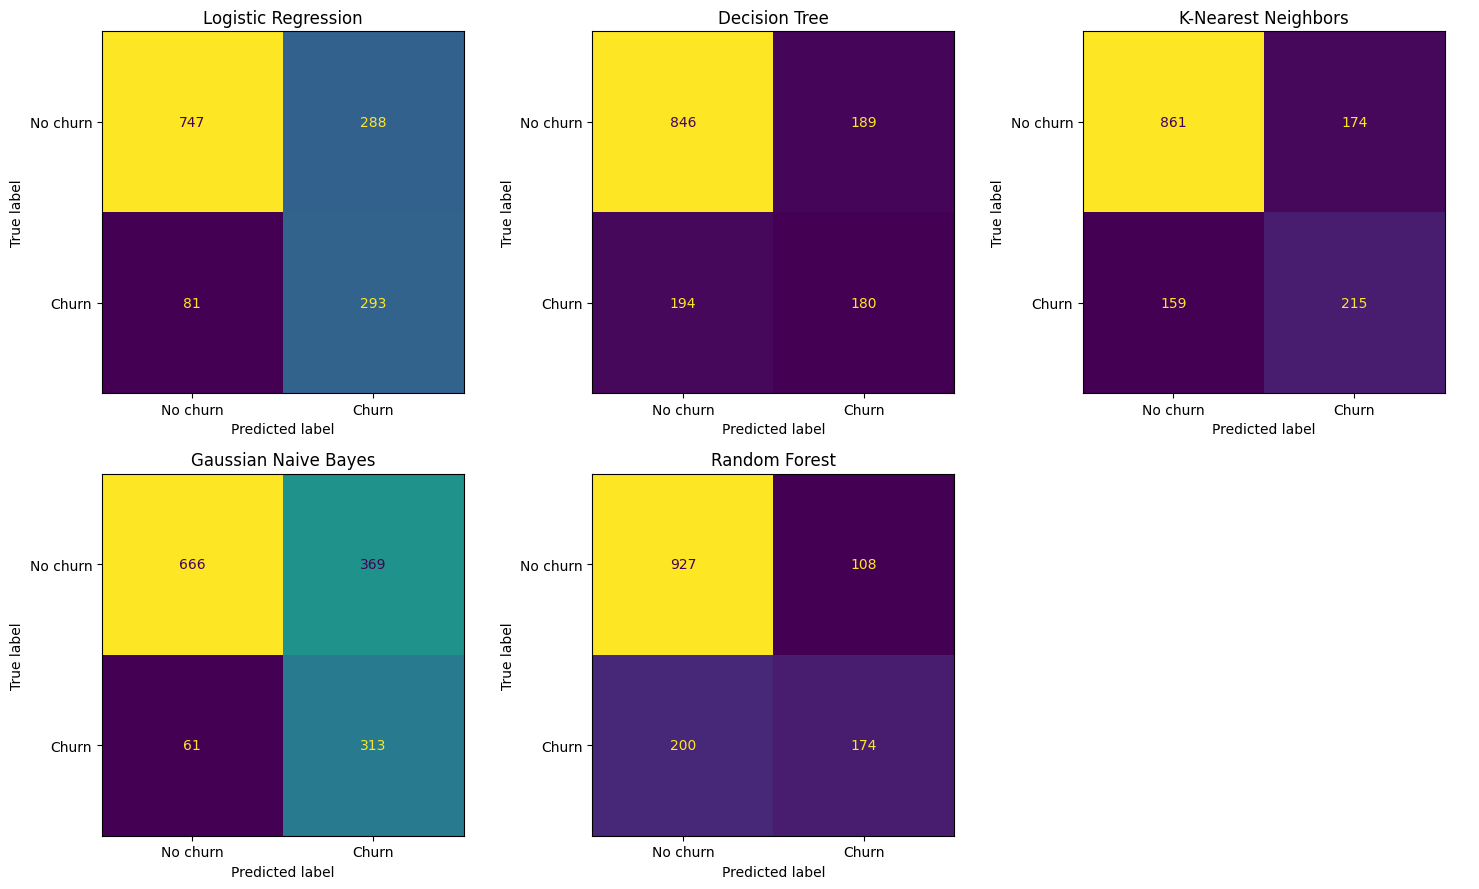


Logistic Regression
              precision    recall  f1-score   support

    No churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Decision Tree
              precision    recall  f1-score   support

    No churn       0.81      0.82      0.82      1035
       Churn       0.49      0.48      0.48       374

    accuracy                           0.73      1409
   macro avg       0.65      0.65      0.65      1409
weighted avg       0.73      0.73      0.73      1409


K-Nearest Neighbors
              precision    recall  f1-score   support

    No churn       0.84      0.83      0.84      1035
       Churn       0.55      0.57      0.56       374

    accuracy                           0.76      1409
   macro avg       0.70      0.70      0.70      1409
weighted avg     

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=["No churn", "Churn"]
    )
    disp.plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(name)

for ax in axes[len(predictions):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

for name, y_pred in predictions.items():
    print("\n" + "=" * 70)
    print(name)
    print(classification_report(
        y_test, y_pred, target_names=["No churn", "Churn"], zero_division=0
    ))


## 11. ROC curves

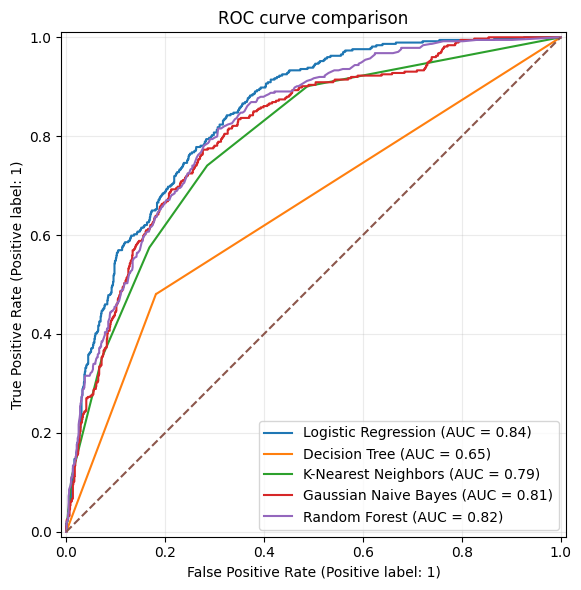

In [29]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, y_prob in probabilities.items():
    RocCurveDisplay.from_predictions(
        y_test, y_prob, name=name, ax=ax
    )
ax.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
ax.set_title("ROC curve comparison")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 12. Model observations and overall winner


For churn prediction, recall for the churn class is important because a false negative means a customer likely to leave was not identified. Precision also matters because unnecessary retention offers may cost the business money. F1 balances precision and recall; AUC measures ranking/discrimination; MCC provides a balanced summary that accounts for all confusion-matrix cells.

The cell below ranks models by F1 as a simple starting point. You should also inspect recall, AUC and MCC before making the final choice.


In [30]:
ranking = results_df.sort_values(
    by=["F1", "Recall", "AUC", "MCC"], ascending=False
)
display(ranking.round(4))

provisional_winner = ranking.index[0]
print("Provisional winner by F1 (tie-breakers: Recall, AUC, MCC):", provisional_winner)
print("\nImportant: review the metric trade-offs and confusion matrices before naming the final winner.")


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.7381,0.8413,0.5043,0.7834,0.6136,0.4531
Gaussian Naive Bayes,0.6948,0.8074,0.4589,0.8369,0.5928,0.4245
K-Nearest Neighbors,0.7637,0.7895,0.5527,0.5749,0.5636,0.4018
Random Forest,0.7814,0.8217,0.6170,0.4652,0.5305,0.3983
Decision Tree,0.7282,0.6496,0.4878,0.4813,0.4845,0.3000


Provisional winner by F1 (tie-breakers: Recall, AUC, MCC): Logistic Regression

Important: review the metric trade-offs and confusion matrices before naming the final winner.


## 12.1 Understanding the metrics before comparing models

The target class is **Churn = Yes** (the positive class). In the test set there are 374 actual churners and 1,035 customers who did not churn. This imbalance matters: a model can obtain a seemingly reasonable accuracy by predicting the majority class (No churn) often, while still missing many customers who actually leave.

| Metric | What it means in this assignment | How to interpret a higher value |
|---|---|---|
| Accuracy | Fraction of all test customers classified correctly, whether they churn or not. | More total predictions are correct. However, accuracy can hide poor churn detection when No churn is the majority class. |
| AUC (ROC-AUC) | How well the model ranks a randomly selected churner above a randomly selected non-churner across possible thresholds. | Closer to 1 means better separation; 0.5 is approximately random ranking. It does not depend on one fixed classification threshold. |
| Precision | Of the customers predicted as churners, how many really churned? | Higher precision means fewer false alarms and less retention effort spent on customers who would stay. |
| Recall | Of all customers who really churned, how many did the model identify? | Higher recall means fewer actual churners are missed. This is especially important when missing a churner is costly. |
| F1-score | Harmonic mean of churn precision and churn recall. | Higher F1 means a better balance between finding churners and avoiding false alarms. |
| MCC | A correlation-style score that uses all four confusion-matrix outcomes (TP, TN, FP and FN). | +1 is perfect, 0 is no better than chance, and -1 is total disagreement. It is useful when classes are imbalanced. |

**Important distinction:** a metric is not simply “good” or “bad” in isolation. Its usefulness depends on the business cost of a false alarm (contacting a customer who would stay) versus a missed churner (failing to contact a customer who leaves).

## 12.2 Detailed observations based on the executed results

The explanations below refer to the held-out test set of **1,409 customers**, including **374 churners**. The values are the actual outputs from the model evaluation cell; precision, recall and F1 refer to the positive class, **Churn = Yes**.

| Model | Measured result | What the result means in practical terms |
|---|---|---|
| **Logistic Regression** | Accuracy **73.81%**, AUC **0.8413**, precision **0.5043**, recall **0.7834**, F1 **0.6136**, MCC **0.4531**. | Its AUC is the highest of the five models, so it has the strongest ability to rank churners above non-churners across thresholds. Recall of 0.7834 means it detects about 78 out of every 100 actual churners (and misses about 22 out of 100). Precision of 0.5043 means about 50 out of every 100 customers it flags as churners really churn; the rest are false alarms. Its F1 and MCC are also the highest, showing the best measured balance and strongest overall agreement with the true labels. Accuracy is only 73.81%, close to the 73.46% majority-class share, so accuracy alone would understate its useful churn detection. **Interpretation:** strongest balanced choice in this experiment, although its alerts include a substantial number of customers who will not churn. |
| **Decision Tree** | Accuracy **72.82%**, AUC **0.6496**, precision **0.4878**, recall **0.4813**, F1 **0.4845**, MCC **0.3000**. | AUC of 0.6496 is the lowest, indicating weaker separation between churners and non-churners than the other models. Recall of 0.4813 means it identifies fewer than half of the actual churners; roughly 52 out of 100 churners are missed. Precision is 0.4878, so fewer than half of its churn alerts are correct. F1 and MCC are also the lowest, which indicates the weakest overall balance/agreement in this comparison. A single test result does **not** prove overfitting; comparing training and validation performance would be needed to establish that. **Interpretation:** weakest model for this dataset and these settings, particularly if the goal is to identify churners. |
| **K-Nearest Neighbors (KNN)** | Accuracy **76.37%**, AUC **0.7895**, precision **0.5527**, recall **0.5749**, F1 **0.5636**, MCC **0.4018**. | It correctly classifies 76.37% of all customers. Among customers flagged as churners, about 55 in 100 really churn (precision); it detects about 57 in 100 actual churners (recall), missing about 43 in 100. Its F1 and MCC are between Logistic Regression and the weaker-performing models, suggesting a moderate, fairly balanced result but not the best churn detection. Because KNN uses distances, scaling numerical inputs is important; the notebook's standard-scaling pipeline addresses differences in feature magnitudes. **Interpretation:** a reasonable middle-performing model, but its churn recall and AUC are lower than Logistic Regression and Gaussian Naive Bayes. |
| **Gaussian Naive Bayes** | Accuracy **69.48%**, AUC **0.8074**, precision **0.4589**, recall **0.8369**, F1 **0.5928**, MCC **0.4245**. | It has the highest recall: it detects about 84 out of every 100 actual churners, missing only about 16 out of 100. This is valuable if the business wants to avoid overlooking customers at risk of leaving. The trade-off is precision of 0.4589: fewer than 46 out of 100 churn alerts are correct, so many non-churners are also flagged. Its accuracy is the lowest, partly reflecting the large number of false-positive alerts generated by its churn-focused predictions. AUC of 0.8074 is still reasonably strong, meaning its probability ranking is useful even though its default class predictions produce many alerts. **Interpretation:** best when catching as many churners as possible matters more than the cost of contacting extra customers. |
| **Random Forest** | Accuracy **78.14%**, AUC **0.8217**, precision **0.6170**, recall **0.4652**, F1 **0.5305**, MCC **0.3983**. | It has the highest accuracy and precision. Accuracy of 78.14% means it makes the largest share of correct predictions overall; precision of 0.6170 means about 62 out of 100 customers it flags as churners really churn, the best rate among these models. However, recall of 0.4652 means it finds fewer than half of all actual churners and misses about 53 out of 100. Its higher accuracy is therefore accompanied by a tendency to classify more customers as non-churners. Its AUC is second-highest, showing good ranking ability, but its F1 and MCC are below Logistic Regression and Gaussian Naive Bayes. **Interpretation:** useful when reducing false churn alerts and obtaining higher overall accuracy are priorities, but not ideal when the main goal is to catch most customers who will leave. |

## 12.3 Overall winner and business recommendation

**Overall winner for this experiment: Logistic Regression.**

This selection is based on the combination of metrics rather than accuracy alone:
- It has the **highest AUC (0.8413)**, so it separates/ranks churners and non-churners best across thresholds.
- It has the **highest F1-score (0.6136)**, the best balance of churn precision and recall at the model's chosen threshold.
- It has the **highest MCC (0.4531)**, the strongest overall correlation between predicted and actual classes among these models.
- Its **recall is 0.7834**, substantially higher than KNN, Decision Tree and Random Forest, while remaining below Gaussian Naive Bayes.

There is no single winner for every business objective:
- If the priority is **catching the greatest number of churners**, choose Gaussian Naive Bayes based on its recall of 0.8369.
- If the priority is **making fewer false churn alerts**, Random Forest has the highest precision (0.6170).
- If the priority is **balanced churn identification**, Logistic Regression is the strongest choice based on F1, AUC and MCC.

The class distribution also explains why accuracy must be interpreted carefully: 73.46% of the dataset belongs to No churn. A simple strategy that always predicted No churn would already achieve about 73.46% accuracy but would have zero recall for churners. Logistic Regression's accuracy is 73.81%, but unlike that trivial strategy it detects 78.34% of actual churners. Therefore, its value is better demonstrated by recall, F1, AUC and MCC than by accuracy alone.

**Conclusion:** Logistic Regression is the recommended overall model for this assignment's measured results. In a real retention campaign, the final model and decision threshold should be selected using the relative cost of missed churners and unnecessary retention contacts. The present comparison uses the models' default prediction thresholds and one stratified hold-out test split; threshold tuning and cross-validation could be explored as further work.


## 13. Save test data, metrics, plots and fitted models

The `test_data.csv` file contains the held-out test features plus the true target label so that the evaluation can be reproduced. Do not use this test file to train or tune the models.

The fitted `.joblib` files contain the complete preprocessing-plus-model pipelines, so new raw customer records can be passed to the saved pipeline.


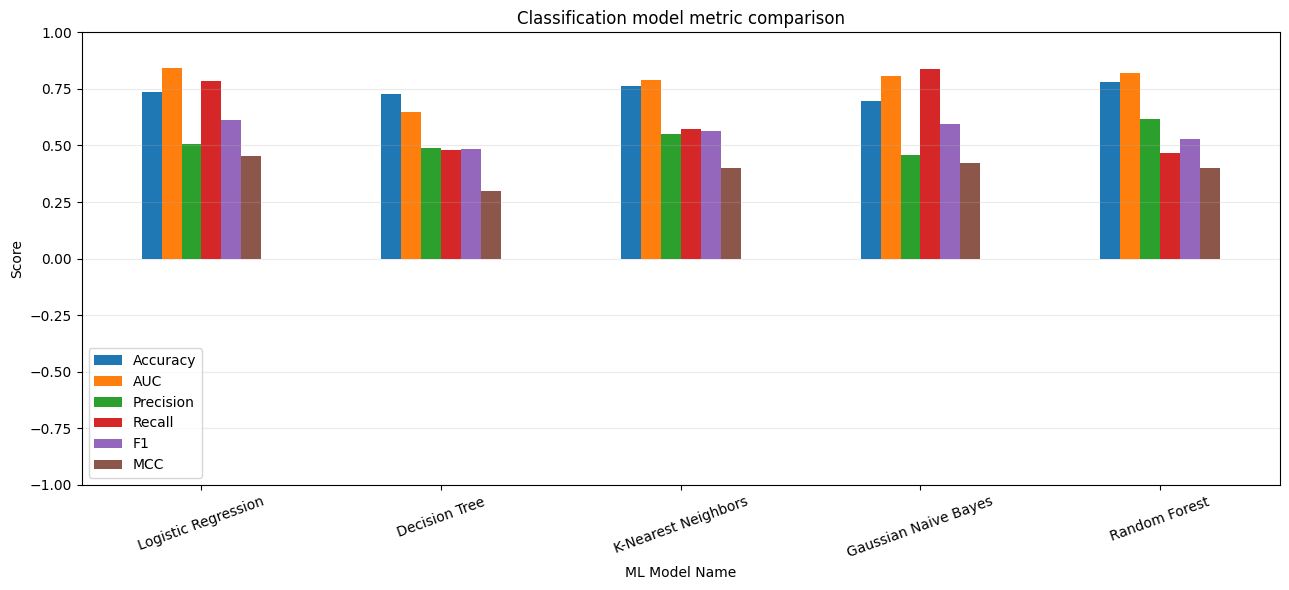

Saved files under: /content/assignment_outputs


In [31]:
OUTPUT_DIR = Path("assignment_outputs")
MODEL_DIR = OUTPUT_DIR / "model"
PLOT_DIR = OUTPUT_DIR / "graphs"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# Save held-out test rows with the actual label for reproducible evaluation.
test_export = X_test.copy()
test_export["Churn"] = y_test.map({0: "No", 1: "Yes"})
test_export.to_csv(OUTPUT_DIR / "test_data.csv", index=False)

# Save metric table.
results_df.to_csv(OUTPUT_DIR / "model_comparison.csv")

# Save all complete pipelines.
model_file_names = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "K-Nearest Neighbors": "knn.joblib",
    "Gaussian Naive Bayes": "naive_bayes.joblib",
    "Random Forest": "random_forest.joblib"
}
for name, fitted_pipeline in fitted_models.items():
    joblib.dump(fitted_pipeline, MODEL_DIR / model_file_names[name])

# Save the main comparison graph.
ax = results_df.plot(kind="bar", figsize=(13, 6), ylim=(-1, 1), rot=20)
ax.set_title("Classification model metric comparison")
ax.set_ylabel("Score")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(PLOT_DIR / "metric_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved files under:", OUTPUT_DIR.resolve())
